In [157]:
# Lädt externe Python-Module vor jedem Zellenausführen automatisch neu
%load_ext autoreload
%autoreload 2

# Macht Matplotlib-Plots interaktiv (Drehen, Zoomen in 3D)
%matplotlib widget

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [158]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, Play, jslink, HBox, IntSlider, interactive_output
from IPython.display import display

# eigenen Module importieren
import nbody.Anfangsbedingungen as ab
import nbody.Dynamik as dyn
import nbody.Integrator as int
import nbody.Analyse as an

# G in SI-Einheiten imporiteren
from scipy.constants import G as G_real


**Berechnung des maximalen Lyapunov-Exponenten**

**Aperiodic**

Die Anfangsbedingungen, sowie die units für die Normierung berechnen

In [159]:
y0_ref_chaos, m_ref_chaos, G, r_ref_chaos, v_ref_chaos = ab.initial_conditions_aperiodic()
units_chaos = an.compute_nbody_units(m_ref_chaos, r_ref_chaos, G)

Parameterwahl

In [160]:
taus = np.array([0.5, 1, 2, 5, 10, 20]) # mgl. Tau werte --> voller Scan durchführen
epsilons_lyap = np.logspace(-9, -4, 6) # mgl. Eps_Lyap Werte --> voller Scan durchführen
n_steps = 2000 # gross genug für stabilen Mittelwert

results_lyap_chaos = {} # {(tau, eps): (lambdas, running_mean, lambda_max)}

for tau in taus:
    for eps in epsilons_lyap:
        lambdas, running_mean, lambda_max = an.compute_lyapunov(y0_ref_chaos, m_ref_chaos, G, units_chaos, eps=eps, tau_norm=tau, n_steps=n_steps, seed=42) # Seed beliebig wählen
        results_lyap_chaos[(tau, eps)] = (lambdas, running_mean, lambda_max)

Identifikation des stabilen Plateaus

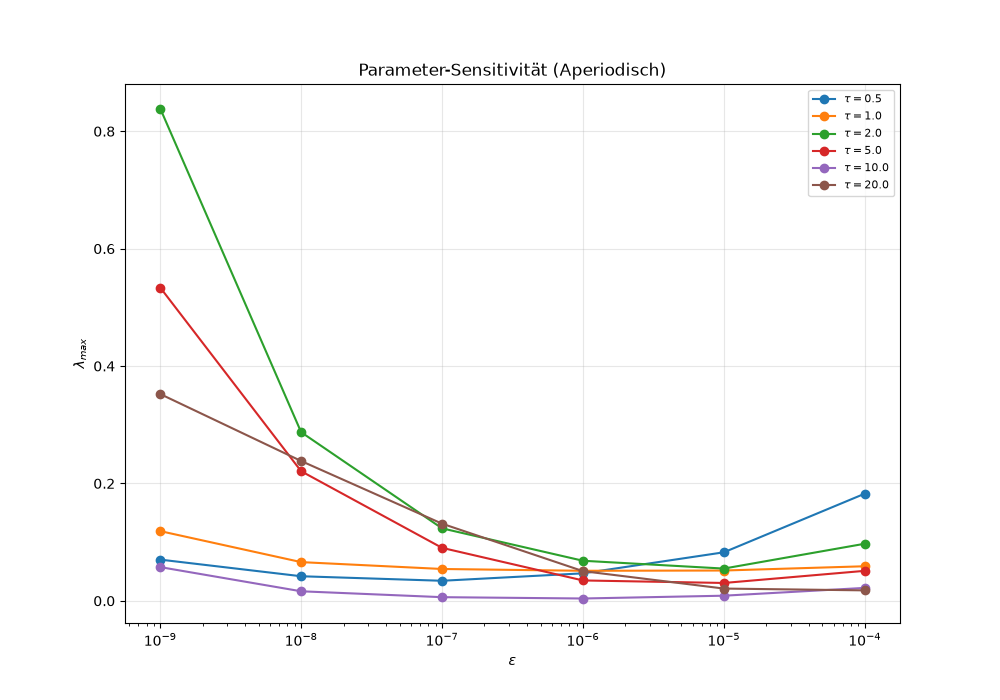

In [188]:
fig, ax = plt.subplots(figsize=(10,7))
for tau in taus:
    lams = [results_lyap_chaos[(tau, eps)][2] for eps in epsilons_lyap]
    ax.semilogx(epsilons_lyap, lams, marker="o", label=f"$\\tau={tau}$")
ax.set_xlabel(r"$\varepsilon$")
ax.set_ylabel(r"$\lambda_{max}$")
ax.set_title("Parameter-Sensitivität (Aperiodisch)")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

In [162]:
for seed in [1, 7, 42, 123, 999]:
    _, _, lam = an.compute_lyapunov(y0_ref_chaos, m_ref_chaos, G, units_chaos,
                                            eps=1e-6, tau_norm=1, n_steps=500, N=3, seed=seed)
    print(f"seed={seed}: lambda_max = {lam:.4f}")

seed=1: lambda_max = 0.2040
seed=7: lambda_max = 0.2071
seed=42: lambda_max = 0.2034
seed=123: lambda_max = 0.2074
seed=999: lambda_max = 0.2012


Plot für die finalen Parameter

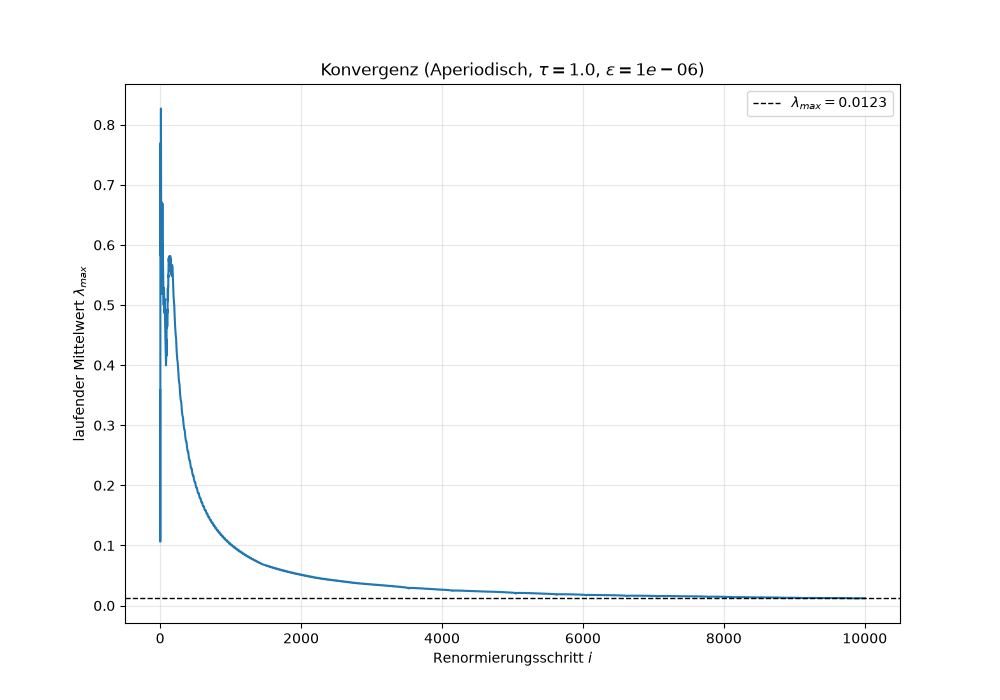

In [200]:
# Durch Plot oben bestimmen
tau_final = 1.0
eps_final = 1e-6

lambdas_f, running_mean_f, lambda_max_f = an.compute_lyapunov(y0_ref_chaos, m_ref_chaos, G, units_chaos, eps=eps_final, tau_norm=tau_final, n_steps=10000, seed=42)

fig, ax = plt.subplots(figsize=(10,7))
ax.plot(np.arange(1, len(running_mean_f)+1), running_mean_f)
ax.axhline(lambda_max_f, color="k", ls="--", lw=1, label=f"$\\lambda_{{max}}={lambda_max_f:.4f}$")
ax.set_xlabel("Renormierungsschritt $i$")
ax.set_ylabel(r"laufender Mittelwert $\lambda_{max}$")
ax.set_title(f"Konvergenz (Aperiodisch, $\\tau={tau_final}$, $\\varepsilon={eps_final:.0e}$)")
ax.legend()
ax.grid(alpha=0.3)

**Lambda_max für Anfang**

In [199]:
# # Durch Plot oben bestimmen
# tau_final = 1.0
# eps_final = 1e-6

# lambdas_f, running_mean_f, lambda_max_f = an.compute_lyapunov(y0_ref_chaos, m_ref_chaos, G, units_chaos, eps=eps_final, tau_norm=tau_final, n_steps=100, seed=42)

# fig, ax = plt.subplots(figsize=(10,7))
# ax.plot(np.arange(1, len(running_mean_f)+1), running_mean_f)
# ax.axhline(lambda_max_f, color="k", ls="--", lw=1, label=f"$\\lambda_{{max}}={lambda_max_f:.4f}$")
# ax.set_xlabel("Renormierungsschritt $i$")
# ax.set_ylabel(r"laufender Mittelwert $\lambda_{max}$")
# ax.set_title(f"Konvergenz (Aperiodisch, $\\tau={tau_final}$, $\\varepsilon={eps_final:.0e}$)")
# ax.legend()
# ax.grid(alpha=0.3)

**Euler**

Die Anfangsbedingungen, sowie die units für die Normierung berechnen

In [165]:
y0_ref_euler, m_ref_euler, G, r_ref_euler, v_ref_euler = ab.initial_conditions_euler()
units_euler = an.compute_nbody_units(m_ref_euler, r_ref_euler, G)

Parameterwahl

In [166]:
taus = np.array([0.5, 1, 2, 5, 10, 20]) # mgl. Tau werte --> voller Scan durchführen
epsilons_lyap = np.logspace(-9, -4, 6) # mgl. Eps_Lyap Werte --> voller Scan durchführen
n_steps = 2000 # gross genug für stabilen Mittelwert

results_lyap_euler = {} 

for tau in taus:
    for eps in epsilons_lyap:
        lambdas_euler, running_mean_euler, lambda_max_euler = an.compute_lyapunov(y0_ref_euler, m_ref_euler, G, units_euler, eps=eps, tau_norm=tau, n_steps=n_steps, seed=42) # Seed beliebig wählen
        results_lyap_euler[(tau, eps)] = (lambdas_euler, running_mean_euler, lambda_max_euler)

Identifikation des stabilen Plateaus

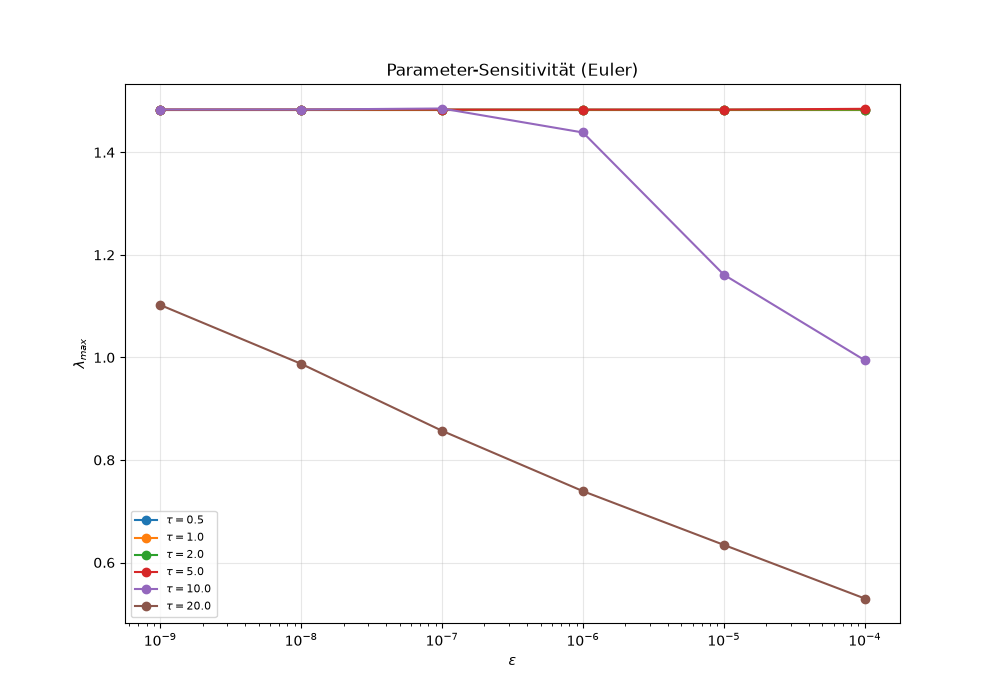

In [191]:
fig, ax = plt.subplots(figsize=(10,7))

for tau in taus:
    lams = [results_lyap_euler[(tau, eps)][2] for eps in epsilons_lyap]
    ax.semilogx(epsilons_lyap, lams, marker="o", label=f"$\\tau={tau}$")
ax.set_xlabel(r"$\varepsilon$")
ax.set_ylabel(r"$\lambda_{max}$")
ax.set_title("Parameter-Sensitivität (Euler)")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

Plot für die finalen Parameter

/var/folders/b_/3c3g0y6s35q6gldtw3gsplbh0000gn/T/ipykernel_4443/3421560204.py:7: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(figsize=(10,7))


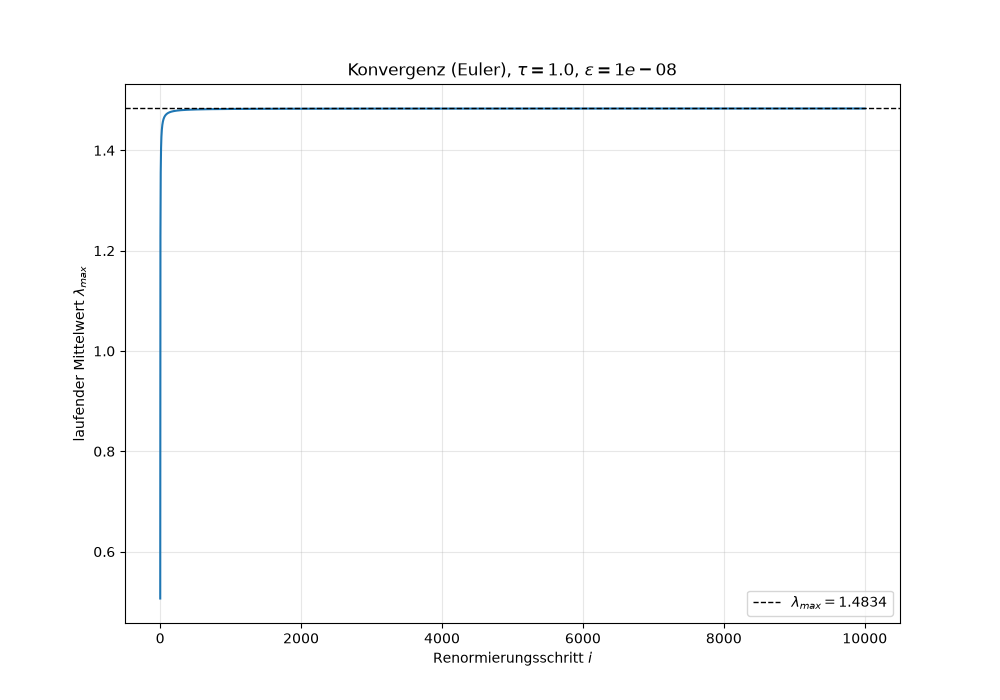

In [197]:
# Durch Plot oben bestimmen
tau_final_euler = 1.0
eps_final_euler = 1e-8

lambdas_f_euler, running_mean_f_euler, lambda_max_f_euler = an.compute_lyapunov(y0_ref_euler, m_ref_euler, G, units_euler, eps=eps_final_euler, tau_norm=tau_final_euler, n_steps=10000, seed=42)

fig, ax = plt.subplots(figsize=(10,7))
ax.plot(np.arange(1, len(running_mean_f_euler)+1), running_mean_f_euler)
ax.axhline(lambda_max_f_euler, color="k", ls="--", lw=1, label=f"$\\lambda_{{max}}={lambda_max_f_euler:.4f}$")
ax.set_xlabel("Renormierungsschritt $i$")
ax.set_ylabel(r"laufender Mittelwert $\lambda_{max}$")
ax.set_title(f"Konvergenz (Euler), $\\tau={tau_final_euler}$, $\\varepsilon={eps_final_euler:.0e}$")
ax.legend()
ax.grid(alpha=0.3)

In [169]:
def diagnose_min_distance(y0_ref_raw, m, G, units, eps, tau_norm, n_steps, N=3, seed=42):
    """Wie compute_lyapunov_benettin, gibt zusaetzlich den min. paarweisen Abstand ueber alle Schritte zurueck."""
    rng = np.random.default_rng(seed)
    tau_raw = tau_norm * units.T0
    y_ref = an.to_norm_state(y0_ref_raw, units, N)
    delta_dir = rng.normal(size=y_ref.shape)
    delta_dir /= np.linalg.norm(delta_dir)
    y_pert = y_ref + eps * delta_dir

    y_ref_raw = y0_ref_raw.copy()
    y_pert_raw = an.to_raw_state(y_pert, units, N)
    min_dists = []

    for i in range(n_steps):
        sol_pert = int.run_n_body_simulation(y_pert_raw, m, G, t_start=0, t_end=tau_raw, frames=2)
        r_pert = sol_pert.y[0:3*N, -1].reshape(N, 3)
        dists = [np.linalg.norm(r_pert[a]-r_pert[b]) for a in range(N) for b in range(a+1,N)]
        min_dists.append(min(dists))

        sol_ref = int.run_n_body_simulation(y_ref_raw, m, G, t_start=0, t_end=tau_raw, frames=2)
        y_ref_raw = sol_ref.y[:, -1]
        y_pert_raw = sol_pert.y[:, -1]
        y_ref  = an.to_norm_state(y_ref_raw, units, N)
        y_pert = an.to_norm_state(y_pert_raw, units, N)
        d_vec = y_pert - y_ref
        d_dir = d_vec / np.linalg.norm(d_vec)
        y_pert_raw = an.to_raw_state(y_ref + eps*d_dir, units, N)

    return np.array(min_dists)

min_d = diagnose_min_distance(y0_ref_euler, m_ref_euler, G, units_euler, eps=1e-6, tau_norm=1.0, n_steps=200)
print("kleinster je aufgetretener Abstand:", min_d.min(), " (Referenzabstand a =", 1.0, ")")

kleinster je aufgetretener Abstand: 0.9999973162943522  (Referenzabstand a = 1.0 )


In [170]:
for seed in [1, 7, 42, 123, 999]:
    _, _, lam = an.compute_lyapunov(y0_ref_euler, m_ref_euler, G, units_euler,
                                            eps=1e-8, tau_norm=0.5, n_steps=500, N=3, seed=seed)
    print(f"seed={seed}: lambda_max = {lam:.4f}")

seed=1: lambda_max = 1.4828
seed=7: lambda_max = 1.4808
seed=42: lambda_max = 1.4794
seed=123: lambda_max = 1.4796
seed=999: lambda_max = 1.4672


**Lagrange**

Die Anfangsbedingungen, sowie die units für die Normierung berechnen

In [186]:
m_ref_lagrange=(1000, 10, 0) 
a_lagrange=1
y0_ref_lagrange, m_ref_lagrange, G, r_ref_lagrange, v_ref_lagrange = ab.initial_conditions_lagrange(m_ref=m_ref_lagrange, a=a_lagrange, G=G)
units_lagrange = an.compute_nbody_units(m_ref_lagrange, r_ref_lagrange, G)

Parameterwahlt

In [187]:
taus = np.array([0.5, 1, 2, 5, 10, 20]) # mgl. Tau werte --> voller Scan durchführen
epsilons_lyap = np.logspace(-9, -4, 6) # mgl. Eps_Lyap Werte --> voller Scan durchführen
n_steps = 2000 # gross genug für stabilen Mittelwert

results_lyap_lagrange = {} 

for tau in taus:
    for eps in epsilons_lyap:
        lambdas_lagrange, running_mean_lagrange, lambda_max_lagrange = an.compute_lyapunov(y0_ref_lagrange, m_ref_lagrange, G, units_lagrange, eps=eps, tau_norm=tau, n_steps=n_steps, seed=42) # Seed beliebig wählen
        results_lyap_lagrange[(tau, eps)] = (lambdas_lagrange, running_mean_lagrange, lambda_max_lagrange)

Identifikation des Plateaus

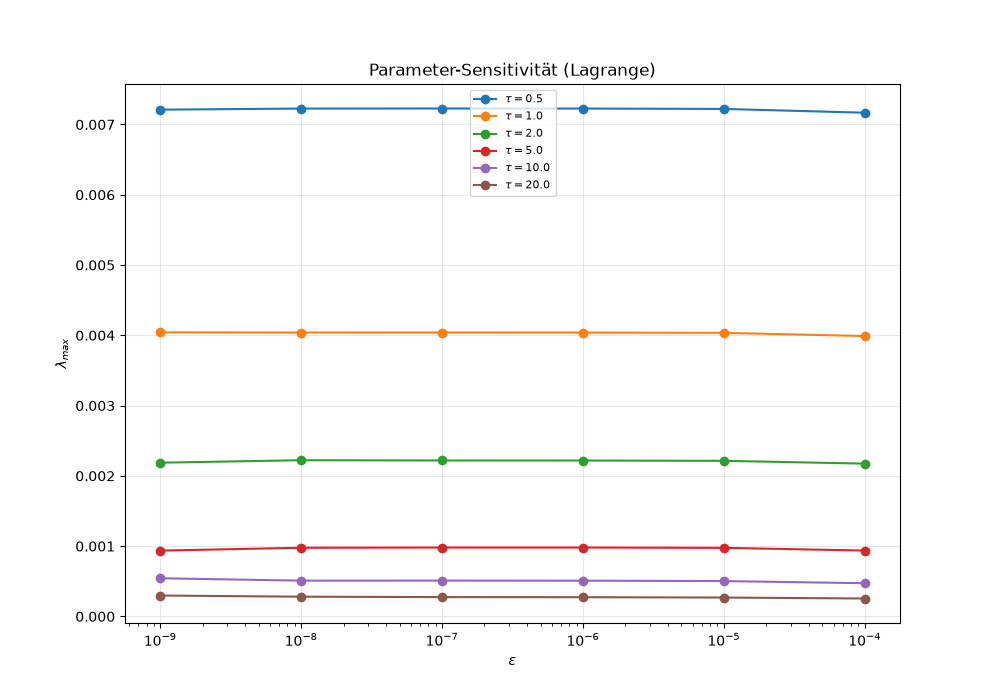

In [193]:
fig, ax = plt.subplots(figsize=(10,7))
for tau in taus:
    lams = [results_lyap_lagrange[(tau, eps)][2] for eps in epsilons_lyap]
    ax.semilogx(epsilons_lyap, lams, marker="o", label=f"$\\tau={tau}$")
ax.set_xlabel(r"$\varepsilon$")
ax.set_ylabel(r"$\lambda_{max}$")
ax.set_title("Parameter-Sensitivität (Lagrange)")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

Plot für die finalen Parameter

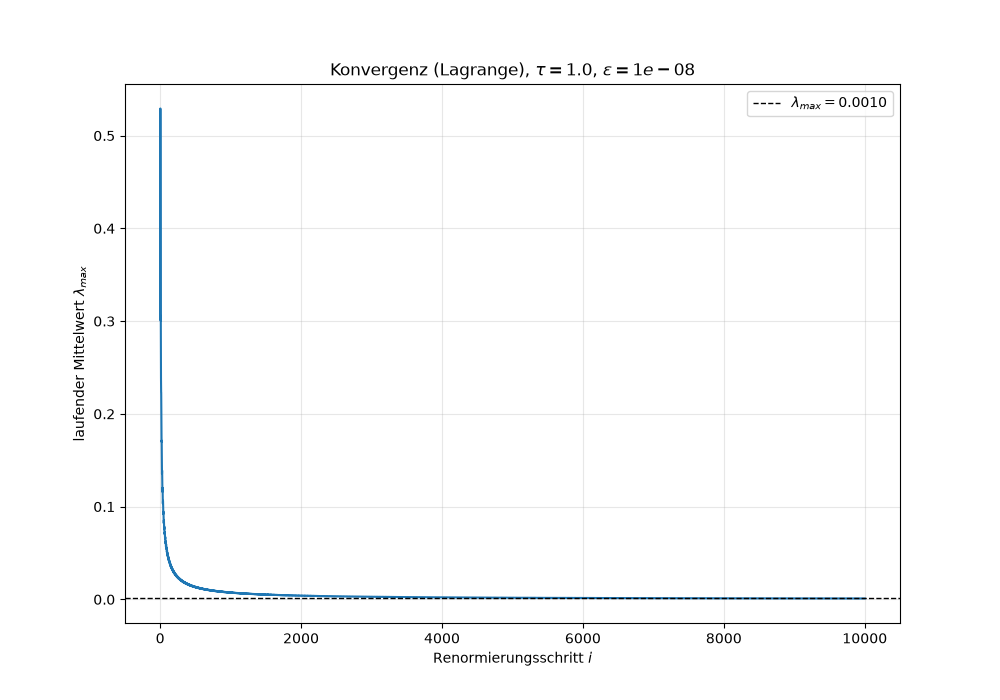

In [198]:
# Durch Plot oben bestimmen
tau_final_lagrange = 1.0
eps_final_lagrange = 1e-8

lambdas_f_lagrange, running_mean_f_lagrange, lambda_max_f_lagrange = an.compute_lyapunov(y0_ref_lagrange, m_ref_lagrange, G, units_lagrange, eps=eps_final_lagrange, tau_norm=tau_final_lagrange, n_steps=10000, seed=42)

fig, ax = plt.subplots(figsize=(10,7))
ax.plot(np.arange(1, len(running_mean_f_lagrange)+1), running_mean_f_lagrange)
ax.axhline(lambda_max_f_lagrange, color="k", ls="--", lw=1, label=f"$\\lambda_{{max}}={lambda_max_f_lagrange:.4f}$")
ax.set_xlabel("Renormierungsschritt $i$")
ax.set_ylabel(r"laufender Mittelwert $\lambda_{max}$")
ax.set_title(f"Konvergenz (Lagrange), $\\tau={tau_final_lagrange}$, $\\varepsilon={eps_final_lagrange:.0e}$")
ax.legend()
ax.grid(alpha=0.3)

**Lyapunov Validierung mit 2BP**

In [175]:
y0_ref_2bp, m_ref_2bp, G, r_ref_2bp, v_ref_2bp = ab.initial_conditions_2bp()
units_2bp = an.compute_nbody_units(m_ref_2bp, r_ref_2bp, G)

Parameterwahl

In [184]:
taus = np.array([0.5, 1, 2, 5, 10, 20]) # mgl. Tau werte --> voller Scan durchführen
epsilons_lyap = np.logspace(-9, -4, 6) # mgl. Eps_Lyap Werte --> voller Scan durchführen
n_steps = 2000 # gross genug für stabilen Mittelwert

results_lyap_2bp = {} 

for tau in taus:
    for eps in epsilons_lyap:
        lambdas_2bp, running_mean_2bp, lambda_max_2bp = an.compute_lyapunov(y0_ref_2bp, m_ref_2bp, G, units_2bp, eps=eps, tau_norm=tau, n_steps=n_steps, seed=42) # Seed beliebig wählen
        results_lyap_2bp[(tau, eps)] = (lambdas_2bp, running_mean_2bp, lambda_max_2bp)

Identifikation des Plateau

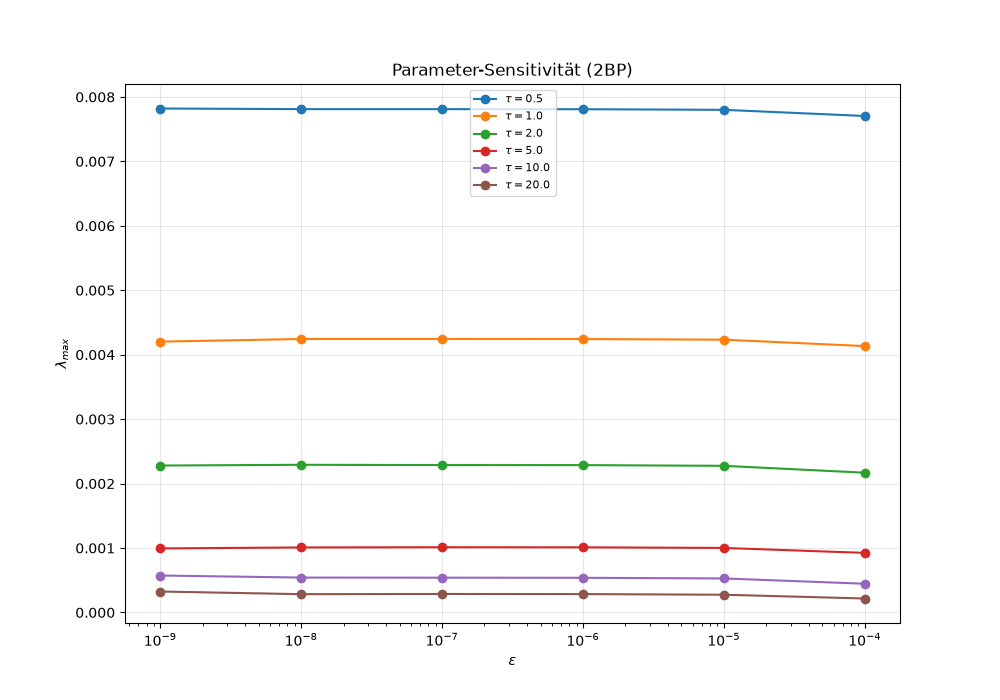

In [195]:
fig, ax = plt.subplots(figsize=(10,7))
for tau in taus:
    lams = [results_lyap_2bp[(tau, eps)][2] for eps in epsilons_lyap]
    ax.semilogx(epsilons_lyap, lams, marker="o", label=f"$\\tau={tau}$")
ax.set_xlabel(r"$\varepsilon$")
ax.set_ylabel(r"$\lambda_{max}$")
ax.set_title("Parameter-Sensitivität (2BP)")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

Plot für die finalen Parameter

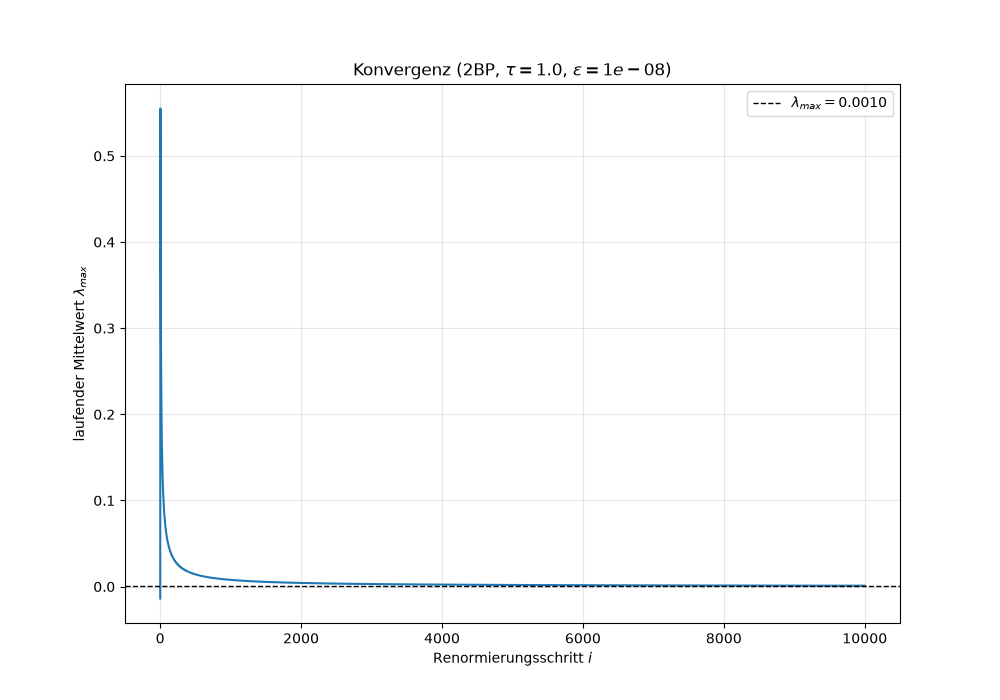

In [196]:
tau_final_2bp = 1.0
eps_final_2bp = 1e-8

lambdas_f_2bp, running_mean_f_2bp, lambda_max_f_2bp = an.compute_lyapunov(y0_ref_2bp, m_ref_2bp, G, units_2bp, eps=eps_final_2bp, tau_norm=tau_final_2bp, n_steps=10000, N=2, seed=42)

fig, ax = plt.subplots(figsize=(10,7))
ax.plot(np.arange(1, len(running_mean_f_2bp)+1), running_mean_f_2bp)
ax.axhline(lambda_max_f_2bp, color="k", ls="--", lw=1, label=f"$\\lambda_{{max}}={lambda_max_f_2bp:.4f}$")
ax.set_xlabel("Renormierungsschritt $i$")
ax.set_ylabel(r"laufender Mittelwert $\lambda_{max}$")
ax.set_title(f"Konvergenz (2BP, $\\tau={tau_final}$, $\\varepsilon={eps_final_2bp:.0e}$)")
ax.legend()
ax.grid(alpha=0.3)


**Vergleich zwischen maximalen Lyapunov Exponenten von Euler, Aperiodisch und Periodisches 2BP**

In [203]:
print(f"Aperiodisch:    \u03bb_max = {lambda_max_f:.4f}")
print(f"Euler:          \u03bb_max = {lambda_max_f_euler:.4f}")
print(f"Lagrange:       \u03bb_max = {lambda_max_f_lagrange:.4f}")
print(f"2BP:            \u03bb_max = {lambda_max_f_2bp:.4f}")

#\u03bb in Unicode für Lambda

Aperiodisch:    λ_max = 0.0123
Euler:          λ_max = 1.4834
Lagrange:       λ_max = 0.0010
2BP:            λ_max = 0.0010


Lyapunov-Zeit

In [204]:
t_lambda_euler = an.lyapunov_time(lambda_max_f_euler)
t_lambda_aperiodic=an.lyapunov_time(lambda_max_f)
t_lambda_lagrange = an.lyapunov_time(lambda_max_f_lagrange)
t_lambda_2bp = an.lyapunov_time(lambda_max_f_2bp)

print(f"Euler:      t_Lambda = {t_lambda_euler:.2f} T0")
print(f"Aperiodic:  t_Lambda = {t_lambda_aperiodic:.2f} T0")
print(f"Lagrange:   t_Lambda = {t_lambda_lagrange:.2f} T0")
print(f"2BP:        t_Lambda = {t_lambda_2bp:.2f} T0")

Euler:      t_Lambda = 0.67 T0
Aperiodic:  t_Lambda = 81.00 T0
Lagrange:   t_Lambda = 1018.26 T0
2BP:        t_Lambda = 989.24 T0


Zeithorizont

In [205]:
t_horizon_euler = an.time_horizon(lambda_max_f_euler, epsilon_0=eps_final_euler, a=1.0)
t_horizon_aperiodic = an.time_horizon(lambda_max_f, epsilon_0=eps_final, a=1.0)
t_horizon_lagrange = an.time_horizon(lambda_max_f_lagrange, epsilon_0=eps_final_lagrange, a=1.0)
t_horizon_2bp = an.time_horizon(lambda_max_f_2bp, epsilon_0=eps_final_2bp, a=1.0)

print(f"Euler:      t_horizon = {t_horizon_euler:.2f} T0")
print(f"Aperiodic:  t_horizon = {t_horizon_aperiodic:.2f} T0")
print(f"Lagrange:   t_horizon = {t_horizon_lagrange:.2f} T0")
print(f"2BP:        t_horizon = {t_horizon_2bp:.2f} T0")

Euler:      t_horizon = 12.42 T0
Aperiodic:  t_horizon = 1119.05 T0
Lagrange:   t_horizon = 18757.10 T0
2BP:        t_horizon = 18222.44 T0


Für Euler, Lagrange und 2BP in Umlaufsperioden

In [207]:
T_euler = an.period_euler(m_ref=1.0, a=1.0, G=G)
n_orbits_t_horizon = t_horizon_euler * units_euler.T0 / T_euler # t_horizon (raw) / Umlaufzeit
n_orbits_T_lambda = t_lambda_euler * units_euler.T0 / T_euler

print(f"Euler:      t_lambda entspricht  {n_orbits_T_lambda:.2f} Umlaufperioden")
print(f"Euler:      t_horizon entspricht {n_orbits_t_horizon:.2f} Umlaufperioden")

print()

T_lagrange = an.period_lagrange(m_ref=m_ref_lagrange, a=a_lagrange, G=G)
n_orbits_t_horizon_lagrange = t_horizon_lagrange * units_lagrange.T0 / T_lagrange # t_horizon (raw) / Umlaufzeit
n_orbits_T_lambda_lagrange = t_lambda_lagrange * units_lagrange.T0 / T_lagrange

print(f"Lagrange:   t_lambda entspricht  {n_orbits_T_lambda_lagrange:.2f} Umlaufperioden")
print(f"Lagrange:   t_horizon entspricht {n_orbits_t_horizon_lagrange:.2f} Umlaufperioden")

print()

T_2bp = an.period_2bp(m_ref_2bp, r_ref_2bp, v_ref_2bp, G)
n_orbits_t_horizon_2bp = t_horizon_2bp * units_2bp.T0 / T_2bp # t_horizon (raw) / Umlaufzeit
n_orbits_T_lambda_2bp = t_lambda_2bp * units_2bp.T0 / T_2bp

print(f"2Bp:        t_lambda entspricht  {n_orbits_T_lambda_2bp:.2f} Umlaufperioden")
print(f"2BP:        t_horizon entspricht {n_orbits_t_horizon_2bp:.2f} Umlaufperioden")

Euler:      t_lambda entspricht  0.09 Umlaufperioden
Euler:      t_horizon entspricht 1.68 Umlaufperioden

Lagrange:   t_lambda entspricht  162.06 Umlaufperioden
Lagrange:   t_horizon entspricht 2985.28 Umlaufperioden

2Bp:        t_lambda entspricht  157.21 Umlaufperioden
2BP:        t_horizon entspricht 2895.84 Umlaufperioden


In [181]:
# plt.close("all")